# Лабораторна робота № 9
## Рекомендаційні системи: SVD та KNNBasic

**ПІБ студента:** Бессараб Марія Павлівна
**Група:** 4-9
**Дата:** 17.11.26

> **Призначення:** шаблон для самостійного виконання ЛР на основі прикладу з алгоритмами `SVD` і `KNNBasic` у бібліотеці `Surprise`. Комірки з позначкою **TODO** потрібно заповнити власним кодом. Це не готовий розв’язок і не заміна офіційної умови роботи.

**Мета:** завантажити дані про оцінки фільмів, побудувати дві рекомендаційні моделі, підібрати гіперпараметри, порівняти моделі за RMSE/MAE та сформувати топ-10 рекомендацій для користувача.

**Дані:** вбудований набір `MovieLens 100K` (`ml-100k`) із бібліотеки `Surprise`.

**Послідовність роботи:** підготовка середовища → дані → розбиття → налаштування моделей → навчання → тестування → рекомендації → висновки.

## 1. Підготовка середовища

Комбінація бібліотек для **Google Colab із Python 3.13**. Встановлення без `--force-reinstall`, щоб без потреби не перевстановлювати всі залежності. Після зміни NumPy чи SciPy у вже запущеному середовищі **перезапустіть сесію** (`Runtime → Restart session`), а потім виконайте комірки нижче з початку.

In [1]:
%pip install -q \
    numpy==2.2.6 \
    scipy==1.15.3 \
    scikit-learn==1.6.1 \
    pandas==2.2.3 \
    scikit-surprise==1.1.5

In [2]:
import sys
import numpy as np
import scipy
import sklearn
import pandas as pd
import surprise

from surprise import Dataset, Reader, SVD, KNNBasic, accuracy
from surprise.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split as sklearn_train_test_split

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('SciPy:', scipy.__version__)
print('scikit-learn:', sklearn.__version__)
print('pandas:', pd.__version__)
print('Surprise:', surprise.__version__)

Python: 3.13.18
NumPy: 2.2.6
SciPy: 1.15.3
scikit-learn: 1.6.1
pandas: 2.2.3
Surprise: 1.1.5


## 2. Завантаження та первинний аналіз даних

1. Завантажте вбудований набір `ml-100k`.
2. Перетворіть оцінки у `pandas.DataFrame` з колонками `user_id`, `item_id`, `rating`, `timestamp`.
3. Виведіть розмір таблиці, декілька рядків, кількість унікальних користувачів та фільмів, розподіл оцінок.

**Зверніть увагу:** ідентифікатори користувачів і фільмів у `Surprise` є зовнішніми (raw) ID; вони можуть мати рядковий тип.

In [3]:
# Завантаження даних (готова частина шаблону)
data = Dataset.load_builtin('ml-100k', prompt=False)

ratings_df = pd.DataFrame(
    data.raw_ratings,
    columns=['user_id', 'item_id', 'rating', 'timestamp']
)

print('Розмір:', ratings_df.shape)
display(ratings_df.head())

Trying to download dataset from https://files.grouplens.org/datasets/movielens/ml-100k.zip...
Done! Dataset ml-100k has been saved to /root/.surprise_data/ml-100k
Розмір: (100000, 4)


,user_id,item_id,rating,timestamp
0,196,242,3.0,881250949
1,186,302,3.0,891717742
2,22,377,1.0,878887116
3,244,51,2.0,880606923
4,166,346,1.0,886397596


In [4]:
# TODO 2.1 — Дослідіть набір даних:
# - кількість унікальних користувачів;
# - кількість унікальних фільмів;
# - мінімальне, максимальне, середнє значення rating;
# - пропущені значення (за наявності).

n_users = ratings_df['user_id'].nunique()
n_items = ratings_df['item_id'].nunique()
density = len(ratings_df) / (n_users * n_items)

print('Типи даних:')
print(ratings_df.dtypes)
print()
print('Унікальних користувачів:', n_users)
print('Унікальних фільмів:', n_items)
print('Мінімальна оцінка:', ratings_df['rating'].min())
print('Максимальна оцінка:', ratings_df['rating'].max())
print('Середня оцінка:', round(ratings_df['rating'].mean(), 4))
print('Медіана оцінок:', ratings_df['rating'].median())
print(f'Заповненість матриці user-item: {density:.4%}')
print()
print('Пропущені значення:')
print(ratings_df.isna().sum())
print()
print('Оцінок на користувача: мін =', ratings_df.groupby('user_id').size().min(),
      ', медіана =', ratings_df.groupby('user_id').size().median())
print('Оцінок на фільм: мін =', ratings_df.groupby('item_id').size().min(),
      ', медіана =', ratings_df.groupby('item_id').size().median())

rating_dist = ratings_df['rating'].value_counts().sort_index().to_frame('count')
rating_dist['share, %'] = (rating_dist['count'] / len(ratings_df) * 100).round(2)
display(rating_dist)

Типи даних:
user_id       object
item_id       object
rating       float64
timestamp     object
dtype: object

Унікальних користувачів: 943
Унікальних фільмів: 1682
Мінімальна оцінка: 1.0
Максимальна оцінка: 5.0
Середня оцінка: 3.5299
Медіана оцінок: 4.0
Заповненість матриці user-item: 6.3047%

Пропущені значення:
user_id      0
item_id      0
rating       0
timestamp    0
dtype: int64

Оцінок на користувача: мін = 20 , медіана = 65.0
Оцінок на фільм: мін = 1 , медіана = 27.0


,count,"share, %"
rating,,
1.0,6110,6.11
2.0,11370,11.37
3.0,27145,27.15
4.0,34174,34.17
5.0,21201,21.20


**Короткі спостереження щодо даних:**

Набір містить 100 000 оцінок від 943 користувачів для 1682 фільмів, пропущених значень немає. Матриця «користувач–фільм» заповнена лише на ≈6,3 %, тобто дані дуже розріджені: кожен користувач оцінив щонайменше 20 фільмів (медіана — 65), тоді як половина фільмів має не більше 27 оцінок, а 333 фільми — менше 5. Оцінки цілі від 1 до 5, середнє — 3,53, медіана — 4; розподіл зміщений у бік позитивних оцінок (4 — 34,2 %, 5 — 21,2 %, 1 — лише 6,1 %).

## 3. Розбиття на навчальну та тестову вибірки

Виконайте випадкове розбиття **80% / 20%** із `random_state=42` за прикладом. Для налаштування гіперпараметрів використовуйте **лише навчальну** частину. Тестова вибірка має залишатися недоторканою до фінальної оцінки.

In [5]:
# TODO 3.1 — Створіть train_df та test_df із ratings_df.
# Використайте sklearn_train_test_split(..., test_size=0.2, random_state=42).

train_df, test_df = sklearn_train_test_split(ratings_df, test_size=0.2, random_state=42)

print('train_df:', train_df.shape)
print('test_df:', test_df.shape)

train_df: (80000, 4)
test_df: (20000, 4)


In [6]:
# TODO 3.2 — Підготуйте об’єкти для Surprise:
# 1. reader = Reader(rating_scale=...)
#    Підказка: data.reader.rating_scale
# 2. train_data = Dataset.load_from_df(...)
#    Візьміть тільки user_id, item_id, rating із train_df.
# 3. testset = список кортежів (user_id, item_id, rating) із test_df.
# 4. Перевірте розміри train/test.

reader = Reader(rating_scale=data.reader.rating_scale)
train_data = Dataset.load_from_df(train_df[['user_id', 'item_id', 'rating']], reader)
testset = list(test_df[['user_id', 'item_id', 'rating']].itertuples(index=False, name=None))

print('Шкала оцінок:', reader.rating_scale)
print('Оцінок у train_data:', len(train_data.raw_ratings))
print('Оцінок у testset:', len(testset))
print('Частка тесту:', round(len(testset) / len(ratings_df), 3))
print('Приклад testset:', testset[:3])

Шкала оцінок: (1, 5)
Оцінок у train_data: 80000
Оцінок у testset: 20000
Частка тесту: 0.2
Приклад testset: [('877', '381', 4.0), ('815', '602', 3.0), ('94', '431', 4.0)]


## 4. Гіперпараметри моделей

Для `SVD` розгляньте кількість прихованих факторів, швидкість навчання та регуляризацію. Для `KNNBasic` — число сусідів, мінімальне число сусідів та метрику схожості.

Нижче — **початкова сітка** з аналізованого прикладу. Її можна змінити й обґрунтувати вибір.

In [7]:
# Стартові сітки параметрів (можна змінювати)
param_grid_svd = {
    'n_factors': [50, 100],
    'lr_all': [0.005, 0.010],
    'reg_all': [0.02, 0.05],
    'random_state': [42]
}

param_grid_knn = {
    'k': [20, 40],
    'min_k': [1, 5],
    'sim_options': {
        'name': ['cosine', 'pearson'],
        'user_based': [False, True]
    },
    'verbose': [False]
}

**Обґрунтування вибору параметрів:**

**SVD**
- `n_factors` ∈ {50, 100} — розмірність латентного простору. Більше факторів дозволяє описати тонші смаки, але на розрідженій матриці підвищує ризик перенавчання.
- `lr_all` ∈ {0.005, 0.010} — крок SGD (0.005 — значення за замовчуванням). За фіксованих 20 епох більший крок дає швидшу збіжність.
- `reg_all` ∈ {0.02, 0.05} — L2-регуляризація біасів і факторів (0.02 — за замовчуванням). Сильніша регуляризація стримує перенавчання для користувачів і фільмів із малою кількістю оцінок.
- `random_state=42` додано для відтворюваності ініціалізації факторів.

**KNNBasic**
- `k` ∈ {20, 40} — максимальна кількість сусідів у прогнозі (40 — за замовчуванням): мале `k` дає шумний прогноз, велике — згладжує його.
- `min_k` ∈ {1, 5} — мінімальна кількість сусідів; якщо їх менше, повертається глобальне середнє.
- `sim_options.name` — косинусна схожість або кореляція Пірсона (Пірсон центрує оцінки й враховує різну «строгість» користувачів).
- `sim_options.user_based` — схожість між користувачами (user-based) або між фільмами (item-based).
- `verbose=False` лише вимикає службові повідомлення про обчислення матриці схожості.

Сітки охоплюють значення за замовчуванням і по одному сусідньому значенню кожного параметра (8 комбінацій для SVD і 16 для KNN) — це компроміс між часом пошуку та якістю. Замість `cv=3` передано `KFold(n_splits=3, random_state=42)`: це ті самі 3 фолди, але однакові для обох моделей і відтворювані при перезапуску.

## 5. Пошук найкращих гіперпараметрів (GridSearchCV)

Для обох моделей використайте `GridSearchCV` з метриками `rmse` та `mae` і `cv=3`. Навчайте об’єкти пошуку **лише на `train_data`**.

In [8]:
# TODO 5.1 — Підберіть гіперпараметри SVD.
# Підказка: GridSearchCV(SVD, param_grid_svd,
#                        measures=['rmse', 'mae'], cv=3, n_jobs=-1)
# Після створення викличте .fit(train_data).

from surprise.model_selection import KFold

cv = KFold(n_splits=3, random_state=42)

grid_search_svd = GridSearchCV(SVD, param_grid_svd, measures=['rmse', 'mae'], cv=cv, n_jobs=-1)
grid_search_svd.fit(train_data)

svd_cv_df = pd.DataFrame(grid_search_svd.cv_results)[['params', 'mean_test_rmse', 'mean_test_mae', 'rank_test_rmse']]
display(svd_cv_df.sort_values('rank_test_rmse'))

,params,mean_test_rmse,mean_test_mae,rank_test_rmse
3,"{'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0...",0.942506,0.744138,1
7,"{'n_factors': 100, 'lr_all': 0.01, 'reg_all': ...",0.946359,0.747109,2
1,"{'n_factors': 50, 'lr_all': 0.005, 'reg_all': ...",0.947724,0.750602,3
5,"{'n_factors': 100, 'lr_all': 0.005, 'reg_all':...",0.949926,0.752114,4
0,"{'n_factors': 50, 'lr_all': 0.005, 'reg_all': ...",0.950164,0.751428,5
4,"{'n_factors': 100, 'lr_all': 0.005, 'reg_all':...",0.955852,0.755293,6
2,"{'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0...",0.968087,0.761514,7
6,"{'n_factors': 100, 'lr_all': 0.01, 'reg_all': ...",0.974105,0.766609,8


In [9]:
# TODO 5.2 — Підберіть гіперпараметри KNNBasic.
# Підказка: використайте param_grid_knn та ті самі метрики/cv.

grid_search_knn = GridSearchCV(KNNBasic, param_grid_knn, measures=['rmse', 'mae'], cv=cv, n_jobs=-1)
grid_search_knn.fit(train_data)

knn_cv_df = pd.DataFrame(grid_search_knn.cv_results)[['params', 'mean_test_rmse', 'mean_test_mae', 'rank_test_rmse']]
display(knn_cv_df.sort_values('rank_test_rmse'))

,params,mean_test_rmse,mean_test_mae,rank_test_rmse
9,"{'k': 40, 'min_k': 1, 'sim_options': {'name': ...",1.027193,0.814330,1
13,"{'k': 40, 'min_k': 5, 'sim_options': {'name': ...",1.028351,0.816193,2
15,"{'k': 40, 'min_k': 5, 'sim_options': {'name': ...",1.030546,0.820138,3
11,"{'k': 40, 'min_k': 1, 'sim_options': {'name': ...",1.032255,0.818751,4
1,"{'k': 20, 'min_k': 1, 'sim_options': {'name': ...",1.035346,0.819590,5
5,"{'k': 20, 'min_k': 5, 'sim_options': {'name': ...",1.036494,0.821453,6
7,"{'k': 20, 'min_k': 5, 'sim_options': {'name': ...",1.036824,0.825208,7
3,"{'k': 20, 'min_k': 1, 'sim_options': {'name': ...",1.038522,0.823821,8
8,"{'k': 40, 'min_k': 1, 'sim_options': {'name': ...",1.045701,0.832236,9
12,"{'k': 40, 'min_k': 5, 'sim_options': {'name': ...",1.045720,0.832338,10


In [10]:
# TODO 5.3 — Виведіть найкращий RMSE, MAE та параметри обох моделей.
# Підказки:
# grid_search_svd.best_score['rmse']
# grid_search_svd.best_params['rmse']
# grid_search_knn.best_score['rmse']

cv_summary = []
for name, gs in [('SVD', grid_search_svd), ('KNNBasic', grid_search_knn)]:
    best_idx = gs.best_index['rmse']
    print(name)
    print('  Найкращий CV RMSE:', round(gs.best_score['rmse'], 4))
    print('  CV MAE для цієї конфігурації:', round(gs.cv_results['mean_test_mae'][best_idx], 4))
    print('  Найкращий CV MAE (окремо):', round(gs.best_score['mae'], 4))
    print('  Параметри за RMSE:', gs.best_params['rmse'])
    print('  Параметри за MAE:', gs.best_params['mae'])
    print()
    cv_summary.append({
        'Model': name,
        'CV RMSE': round(gs.best_score['rmse'], 4),
        'CV MAE': round(gs.cv_results['mean_test_mae'][best_idx], 4),
        'Best params (RMSE)': gs.best_params['rmse']
    })

cv_summary_df = pd.DataFrame(cv_summary)
display(cv_summary_df)

SVD
  Найкращий CV RMSE: 0.9425
  CV MAE для цієї конфігурації: 0.7441
  Найкращий CV MAE (окремо): 0.7441
  Параметри за RMSE: {'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0.05, 'random_state': 42}
  Параметри за MAE: {'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0.05, 'random_state': 42}

KNNBasic
  Найкращий CV RMSE: 1.0272
  CV MAE для цієї конфігурації: 0.8143
  Найкращий CV MAE (окремо): 0.8143
  Параметри за RMSE: {'k': 40, 'min_k': 1, 'sim_options': {'name': 'cosine', 'user_based': True}, 'verbose': False}
  Параметри за MAE: {'k': 40, 'min_k': 1, 'sim_options': {'name': 'cosine', 'user_based': True}, 'verbose': False}



,Model,CV RMSE,CV MAE,Best params (RMSE)
0,SVD,0.9425,0.7441,"{'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0..."
1,KNNBasic,1.0272,0.8143,"{'k': 40, 'min_k': 1, 'sim_options': {'name': ..."


**Аналіз результатів кросвалідації:**

| Модель | Найкращий CV RMSE | CV MAE | Найкращі параметри за RMSE |
|---|---:|---:|---|
| SVD | 0.9425 | 0.7441 | `n_factors=50`, `lr_all=0.01`, `reg_all=0.05` |
| KNNBasic | 1.0272 | 0.8143 | `k=40`, `min_k=1`, `cosine`, `user_based=True` |

SVD на кросвалідації суттєво точніша за KNNBasic: RMSE нижчий на 0.085 (≈8 %), MAE — на 0.070. Для обох моделей найкращі параметри за RMSE і за MAE збіглися.

Для SVD вирішальною виявилась регуляризація: усі чотири конфігурації з `reg_all=0.05` кращі за будь-яку з `reg_all=0.02`, а поєднання великого кроку `lr_all=0.01` зі слабкою регуляризацією дало найгірший результат (RMSE 0.968–0.974) — модель перенавчається. За інших рівних 50 факторів стабільно трохи кращі за 100.

Для KNNBasic user-based підхід помітно кращий за item-based (RMSE 1.027–1.039 проти 1.046–1.073), `k=40` кращий за `k=20`, косинусна схожість трохи випереджає Пірсона, а `min_k` майже не впливає на результат (різниця ≤ 0.0012).

## 6. Навчання остаточних моделей

Побудуйте `trainset = train_data.build_full_trainset()`. Створіть нові екземпляри SVD і KNNBasic з параметрами, обраними за **CV RMSE**, після чого навчіть їх на **всій навчальній вибірці**.

In [11]:
# TODO 6.1 — Отримайте best_svd_params і best_knn_params за CV RMSE.
# TODO 6.2 — Створіть trainset із train_data.
# TODO 6.3 — Навчіть best_svd і best_knn.
# Для відтворюваності задайте random_state=42 для SVD.

best_svd_params = dict(grid_search_svd.best_params['rmse'])
best_svd_params['random_state'] = 42
best_knn_params = dict(grid_search_knn.best_params['rmse'])

trainset = train_data.build_full_trainset()
print('Користувачів у trainset:', trainset.n_users)
print('Фільмів у trainset:', trainset.n_items)
print('Оцінок у trainset:', trainset.n_ratings)

best_svd = SVD(**best_svd_params)
best_svd.fit(trainset)

best_knn = KNNBasic(**best_knn_params)
best_knn.fit(trainset)

print()
print('SVD навчено з параметрами:', best_svd_params)
print('KNNBasic навчено з параметрами:', best_knn_params)

Користувачів у trainset: 943
Фільмів у trainset: 1653
Оцінок у trainset: 80000

SVD навчено з параметрами: {'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0.05, 'random_state': 42}
KNNBasic навчено з параметрами: {'k': 40, 'min_k': 1, 'sim_options': {'name': 'cosine', 'user_based': True}, 'verbose': False}


## 7. Оцінювання на незалежній тестовій вибірці

Отримайте передбачення для `testset` методами `.test()` обох моделей. Обчисліть `RMSE` та `MAE` за допомогою `surprise.accuracy`.

**Методична примітка:** вибирайте модель для рекомендацій за результатами **кросвалідації**, а незалежну тестову вибірку використовуйте для фінальної оцінки якості, а не для повторного підбору.

In [12]:
# TODO 7.1 — Отримайте svd_predictions та knn_predictions.
# TODO 7.2 — Обчисліть svd_rmse, svd_mae, knn_rmse, knn_mae.
# Підказка: accuracy.rmse(predictions, verbose=False)
#           accuracy.mae(predictions, verbose=False)

svd_predictions = best_svd.test(testset)
knn_predictions = best_knn.test(testset)

svd_rmse = accuracy.rmse(svd_predictions, verbose=False)
svd_mae = accuracy.mae(svd_predictions, verbose=False)
knn_rmse = accuracy.rmse(knn_predictions, verbose=False)
knn_mae = accuracy.mae(knn_predictions, verbose=False)

print(f'SVD:      RMSE = {svd_rmse:.4f}, MAE = {svd_mae:.4f}')
print(f'KNNBasic: RMSE = {knn_rmse:.4f}, MAE = {knn_mae:.4f}')

knn_impossible = sum(p.details.get('was_impossible', False) for p in knn_predictions)
print(f'KNNBasic: прогнозів за замовчуванням (недостатньо сусідів/невідомі ID): {knn_impossible} з {len(knn_predictions)}')

SVD:      RMSE = 0.9192, MAE = 0.7234
KNNBasic: RMSE = 1.0120, MAE = 0.7984
KNNBasic: прогнозів за замовчуванням (недостатньо сусідів/невідомі ID): 31 з 20000


In [13]:
# TODO 7.3 — Сформуйте DataFrame results із колонками:
# Model, RMSE, MAE.
# Відсортуйте за RMSE та покажіть порівняння.

results = pd.DataFrame({
    'Model': ['SVD', 'KNNBasic'],
    'RMSE': [svd_rmse, knn_rmse],
    'MAE': [svd_mae, knn_mae]
}).sort_values('RMSE').reset_index(drop=True).round(4)
display(results)

cv_vs_test = pd.DataFrame({
    'Model': ['SVD', 'KNNBasic'],
    'CV RMSE': [grid_search_svd.best_score['rmse'], grid_search_knn.best_score['rmse']],
    'Test RMSE': [svd_rmse, knn_rmse],
    'CV MAE': [grid_search_svd.cv_results['mean_test_mae'][grid_search_svd.best_index['rmse']],
               grid_search_knn.cv_results['mean_test_mae'][grid_search_knn.best_index['rmse']]],
    'Test MAE': [svd_mae, knn_mae]
})
cv_vs_test['Δ RMSE (test − CV)'] = cv_vs_test['Test RMSE'] - cv_vs_test['CV RMSE']
cv_vs_test['Δ MAE (test − CV)'] = cv_vs_test['Test MAE'] - cv_vs_test['CV MAE']
display(cv_vs_test.round(4))

,Model,RMSE,MAE
0,SVD,0.9192,0.7234
1,KNNBasic,1.0120,0.7984


,Model,CV RMSE,Test RMSE,CV MAE,Test MAE,Δ RMSE (test − CV),Δ MAE (test − CV)
0,SVD,0.9425,0.9192,0.7441,0.7234,-0.0233,-0.0208
1,KNNBasic,1.0272,1.0120,0.8143,0.7984,-0.0152,-0.0159


**Таблиця тестових результатів:**

| Модель | Test RMSE | Test MAE |
|---|---:|---:|
| SVD | 0.9192 | 0.7234 |
| KNNBasic | 1.0120 | 0.7984 |

**Порівняння з CV:** оцінки на незалежній тестовій вибірці навіть трохи кращі за кросвалідаційні: для SVD RMSE нижчий на 0.0233, MAE — на 0.0208; для KNNBasic — на 0.0152 і 0.0159 відповідно. Різниця невелика (≈1,5–2,5 %) і очікувана: під час CV кожна модель навчалася лише на 2/3 навчальної вибірки (≈53 тис. оцінок), а остаточні моделі — на всіх 80 тис., тому фактори та схожості оцінені точніше. Порядок моделей не змінився (SVD краща на 0.093 RMSE), отже вибір за CV підтверджується, ознак перенавчання на тест немає. Лише 31 тестова пара з 20 000 (фільми, яких немає в train) для KNNBasic отримала прогноз за замовчуванням.

## 8. Топ-10 рекомендацій для користувача

1. Оберіть модель із кращим **CV RMSE**.
2. Задайте `user_id` (вихідний приклад використовує `'196'`).
3. Отримайте фільми, які цей користувач уже оцінив у навчальній вибірці.
4. Для решти фільмів обчисліть прогнозований рейтинг `.predict(uid=..., iid=...).est`.
5. Виведіть **10 фільмів із найбільшим прогнозованим рейтингом**.

**Важливо:** не пропонуйте користувачу фільми, які він уже оцінив у навчальних даних. Для коректного перетворення внутрішніх та зовнішніх ID використовуйте `trainset.to_inner_uid()`, `trainset.to_raw_iid()`.

In [14]:
# Початковий ID можна змінити
user_id = '196'

# TODO 8.1 — Визначте найкращу за CV RMSE модель.
# TODO 8.2 — Перевірте, що користувач присутній у trainset.
# TODO 8.3 — Знайдіть неоцінені ним фільми.
# TODO 8.4 — Спрогнозуйте оцінки та покажіть топ-10.
# Бажані колонки результату: item_id, predicted_rating.
# Передбачте ситуацію, коли обраного user_id немає у trainset.

import os

cv_rmse_scores = {
    'SVD': grid_search_svd.best_score['rmse'],
    'KNNBasic': grid_search_knn.best_score['rmse']
}
best_model_name = min(cv_rmse_scores, key=cv_rmse_scores.get)
best_model = {'SVD': best_svd, 'KNNBasic': best_knn}[best_model_name]
print(f'Модель для рекомендацій: {best_model_name} (CV RMSE = {cv_rmse_scores[best_model_name]:.4f})')

item_titles = {}
items_path = os.path.join(os.path.expanduser('~'), '.surprise_data', 'ml-100k', 'ml-100k', 'u.item')
if os.path.exists(items_path):
    items_df = pd.read_csv(items_path, sep='|', encoding='latin-1', header=None,
                           usecols=[0, 1], names=['item_id', 'title'], dtype={'item_id': str})
    item_titles = dict(zip(items_df['item_id'], items_df['title']))


def add_titles(df):
    if item_titles:
        df.insert(1, 'title', df['item_id'].map(item_titles))
    return df


def popular_items(n=10, min_count=50):
    stats = train_df.groupby('item_id')['rating'].agg(['mean', 'count'])
    top = stats[stats['count'] >= min_count].sort_values('mean', ascending=False).head(n)
    df = pd.DataFrame({'item_id': top.index, 'predicted_rating': top['mean'].round(4).values})
    df.index = range(1, len(df) + 1)
    return add_titles(df)


def get_top_n(model, trainset, uid, n=10):
    try:
        inner_uid = trainset.to_inner_uid(uid)
    except ValueError:
        print(f'Користувача {uid} немає у trainset — показано найпопулярніші фільми (cold start).')
        return popular_items(n)

    rated_items = {trainset.to_raw_iid(inner_iid) for inner_iid, _ in trainset.ur[inner_uid]}
    candidates = [trainset.to_raw_iid(inner_iid) for inner_iid in trainset.all_items()
                  if trainset.to_raw_iid(inner_iid) not in rated_items]
    print(f'Користувач {uid}: оцінено у train — {len(rated_items)}, кандидатів для рекомендації — {len(candidates)}')

    predictions = [(iid, model.predict(uid=uid, iid=iid).est) for iid in candidates]
    top = sorted(predictions, key=lambda x: x[1], reverse=True)[:n]

    df = pd.DataFrame(top, columns=['item_id', 'predicted_rating'])
    df['predicted_rating'] = df['predicted_rating'].round(4)
    df.index = range(1, len(df) + 1)
    return add_titles(df)


top10 = get_top_n(best_model, trainset, user_id, n=10)
display(top10)

user_train_items = set(train_df.loc[train_df['user_id'] == user_id, 'item_id'])
print('Перетин рекомендацій з уже оціненими фільмами:', len(set(top10['item_id']) & user_train_items))

print()
display(get_top_n(best_model, trainset, '99999', n=10))

Модель для рекомендацій: SVD (CV RMSE = 0.9425)
Користувач 196: оцінено у train — 29, кандидатів для рекомендації — 1624


,item_id,title,predicted_rating
1,320,Paradise Lost: The Child Murders at Robin Hood...,4.4904
2,64,"Shawshank Redemption, The (1994)",4.4707
3,480,North by Northwest (1959),4.4137
4,313,Titanic (1997),4.4019
5,513,"Third Man, The (1949)",4.3996
6,483,Casablanca (1942),4.3981
7,318,Schindler's List (1993),4.3921
8,656,M (1931),4.3854
9,22,Braveheart (1995),4.3774
10,272,Good Will Hunting (1997),4.3760


Перетин рекомендацій з уже оціненими фільмами: 0

Користувача 99999 немає у trainset — показано найпопулярніші фільми (cold start).


,item_id,title,predicted_rating
1,114,Wallace & Gromit: The Best of Aardman Animatio...,4.5098
2,318,Schindler's List (1993),4.4746
3,64,"Shawshank Redemption, The (1994)",4.4561
4,483,Casablanca (1942),4.4286
5,408,"Close Shave, A (1995)",4.4167
6,12,"Usual Suspects, The (1995)",4.4110
7,169,"Wrong Trousers, The (1993)",4.3871
8,134,Citizen Kane (1941),4.3797
9,603,Rear Window (1954),4.3772
10,50,Star Wars (1977),4.3703


## 9. Перевірка виконання

Позначте після реалізації:

- [x] Дані `ml-100k` завантажено та перевірено.
- [x] Є розбиття 80/20 з фіксованим `random_state`.
- [x] `Reader`, `train_data` і `testset` створені коректно.
- [x] GridSearchCV для **обох** моделей виконано лише на `train_data`.
- [x] Для SVD і KNNBasic показано параметри та результати CV.
- [x] Моделі навчено на повній навчальній частині.
- [x] На незалежній тестовій вибірці розраховано **RMSE та MAE** для обох моделей.
- [x] Наведено порівняльну таблицю та інтерпретацію.
- [x] Сформовано топ-10 рекомендацій без уже оцінених фільмів.
- [x] Усі комірки виконуються послідовно після перезапуску середовища.

## 10. Висновки

1. **Яку модель обрано за кросвалідацією і чому?** SVD — вона має найменший CV RMSE (0.9425 проти 1.0272 у KNNBasic) і менший CV MAE (0.7441 проти 0.8143).
2. **Найкращі гіперпараметри:** SVD — `n_factors=50`, `lr_all=0.01`, `reg_all=0.05`; KNNBasic — `k=40`, `min_k=1`, косинусна схожість, user-based.
3. **Тестові метрики:** SVD — RMSE 0.9192, MAE 0.7234; KNNBasic — RMSE 1.0120, MAE 0.7984.
4. **CV vs тест:** тестові оцінки на 0.015–0.023 кращі за CV, бо остаточні моделі навчені на повних 80 тис. оцінок, а не на 2/3 вибірки; ранжування моделей збігається.
5. **Обмеження:** для нового користувача (немає в trainset) персоналізація неможлива — реалізовано запасний варіант із найпопулярнішими фільмами; 29 фільмів, яких немає в trainset, не можуть потрапити до рекомендацій. Рекомендації спираються лише на оцінки (без жанрів, часу, контексту), модель статична, а RMSE/MAE оцінюють точність рейтингу, а не якість саме топ-N списку.

**Висновок:** У роботі на даних MovieLens 100K (943 користувачі, 1682 фільми, заповненість матриці ≈6,3 %) порівняно моделі SVD і KNNBasic з підбором гіперпараметрів через 3-фолдову кросвалідацію лише на навчальній частині. SVD суттєво випередила KNNBasic як на CV (RMSE 0.9425 проти 1.0272), так і на незалежному тесті (RMSE 0.9192 / MAE 0.7234 проти 1.0120 / 0.7984), тобто її прогноз у середньому помиляється приблизно на 0,72 бала за 5-бальною шкалою. Найважливішим параметром SVD виявилась регуляризація `reg_all=0.05`, що узгоджується з високою розрідженістю даних; для KNN найбільше вплинув вибір user-based схожості та `k=40`. Тестові метрики трохи кращі за CV, що пояснюється більшим обсягом даних для навчання остаточних моделей, і свідчить про відсутність перенавчання на етапі підбору. Для користувача 196 модель SVD сформувала топ-10 із 1624 неоцінених ним фільмів (прогнози 4.38–4.49), жоден із них не перетинається з уже оціненими. Список складається переважно з високо оцінених класичних фільмів, що показує сильний вплив біасів фільмів і схильність моделі до популярного контенту. Основні обмеження — проблема холодного старту для нових користувачів і фільмів та відсутність оцінки якості саме ранжування (precision@k, recall@k).

---
**Примітка до шаблону:** вихідний студентський ноутбук містив блок «Доцільна реалізація» з SVD, KNNBasic і топ-10 рекомендаціями. Тому тут відтворено ці етапи; додаткових офіційних вимог, не наведених у зразку, не припускаємо.

**Додаткове завдання. Написати власний рекомендаційний алгоритм з нуля**

**Опис алгоритму.** Реалізовано з нуля (лише NumPy, без Surprise) матричну факторизацію з біасами (FunkSVD), яку навчено стохастичним градієнтним спуском.

Прогноз оцінки користувача $u$ для фільму $i$:

$$\hat r_{ui} = \mu + b_u + b_i + p_u^\top q_i,$$

де $\mu$ — середня оцінка в train, $b_u, b_i$ — зміщення користувача та фільму, $p_u, q_i$ — вектори латентних факторів.

Функція втрат з L2-регуляризацією:

$$\min \sum_{(u,i)\in R_{train}} \left(r_{ui} - \hat r_{ui}\right)^2 + \lambda\left(b_u^2 + b_i^2 + \lVert p_u\rVert^2 + \lVert q_i\rVert^2\right)$$

Для кожної оцінки в перемішаному порядку обчислюється похибка $e_{ui} = r_{ui} - \hat r_{ui}$ і параметри оновлюються:

$$b_u \leftarrow b_u + \gamma(e_{ui} - \lambda b_u),\quad b_i \leftarrow b_i + \gamma(e_{ui} - \lambda b_i)$$
$$p_u \leftarrow p_u + \gamma(e_{ui} q_i - \lambda p_u),\quad q_i \leftarrow q_i + \gamma(e_{ui} p_u - \lambda q_i)$$

Особливості реалізації:
- `n_factors=0` перетворює модель на baseline, що враховує лише $\mu + b_u + b_i$ — для порівняння внеску латентних факторів.
- Гіперпараметри FunkSVD взято з найкращої за CV конфігурації SVD (`n_factors=50`, $\gamma=0.01$, $\lambda=0.05$, 20 епох, ініціалізація з нормального розподілу $N(0,\ 0.1)$), тож тестова вибірка для підбору не використовувалась.
- Для невідомого користувача чи фільму прогноз будується з наявних складових ($\mu$ і відомого біасу), результат обрізається до шкали $[1, 5]$.
- Рекомендації обчислюються векторно для всіх фільмів, уже оцінені користувачем у train виключаються.

In [17]:
class FunkSVDFromScratch:
    def __init__(self, n_factors=50, n_epochs=20, lr=0.005, reg=0.02, init_std=0.1,
                 rating_scale=(1, 5), random_state=42):
        self.n_factors = n_factors
        self.n_epochs = n_epochs
        self.lr = lr
        self.reg = reg
        self.init_std = init_std
        self.rating_scale = rating_scale
        self.random_state = random_state

    def fit(self, df, verbose=True):
        self.user_index = {u: idx for idx, u in enumerate(df['user_id'].unique())}
        self.item_index = {i: idx for idx, i in enumerate(df['item_id'].unique())}
        self.index_item = {idx: i for i, idx in self.item_index.items()}

        users = df['user_id'].map(self.user_index).to_numpy()
        items = df['item_id'].map(self.item_index).to_numpy()
        ratings = df['rating'].to_numpy(dtype=np.float64)

        rng = np.random.default_rng(self.random_state)
        n_users, n_items = len(self.user_index), len(self.item_index)

        self.global_mean = ratings.mean()
        self.bu = np.zeros(n_users)
        self.bi = np.zeros(n_items)
        self.P = rng.normal(0, self.init_std, (n_users, self.n_factors))
        self.Q = rng.normal(0, self.init_std, (n_items, self.n_factors))
        self.train_rmse_history = []

        lr, reg = self.lr, self.reg
        for epoch in range(self.n_epochs):
            for idx in rng.permutation(len(ratings)):
                u, i = users[idx], items[idx]
                pu = self.P[u].copy()
                qi = self.Q[i]
                err = ratings[idx] - (self.global_mean + self.bu[u] + self.bi[i] + pu @ qi)

                self.bu[u] += lr * (err - reg * self.bu[u])
                self.bi[i] += lr * (err - reg * self.bi[i])
                self.P[u] = pu + lr * (err * qi - reg * pu)
                self.Q[i] = qi + lr * (err * pu - reg * qi)

            train_pred = (self.global_mean + self.bu[users] + self.bi[items]
                          + np.einsum('ij,ij->i', self.P[users], self.Q[items]))
            train_pred = np.clip(train_pred, *self.rating_scale)
            train_rmse = np.sqrt(np.mean((ratings - train_pred) ** 2))
            self.train_rmse_history.append(train_rmse)
            if verbose and ((epoch + 1) % 5 == 0 or epoch == 0):
                print(f'Епоха {epoch + 1:>2}/{self.n_epochs}: train RMSE = {train_rmse:.4f}')
        return self

    def predict(self, user_id, item_id):
        u = self.user_index.get(user_id)
        i = self.item_index.get(item_id)
        est = self.global_mean
        if u is not None:
            est += self.bu[u]
        if i is not None:
            est += self.bi[i]
        if u is not None and i is not None:
            est += self.P[u] @ self.Q[i]
        return float(np.clip(est, *self.rating_scale))

    def predict_df(self, df):
        return np.array([self.predict(u, i) for u, i in zip(df['user_id'], df['item_id'])])

    def recommend(self, user_id, exclude_items, n=10):
        u = self.user_index.get(user_id)
        if u is None:
            return None
        scores = self.global_mean + self.bu[u] + self.bi + self.Q @ self.P[u]
        scores = np.clip(scores, *self.rating_scale)
        recs = []
        for idx in np.argsort(-scores):
            item_id = self.index_item[idx]
            if item_id not in exclude_items:
                recs.append((item_id, round(float(scores[idx]), 4)))
            if len(recs) == n:
                break
        df = pd.DataFrame(recs, columns=['item_id', 'predicted_rating'])
        df.index = range(1, len(df) + 1)
        return df


def rmse_mae(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    return np.sqrt(np.mean((y_true - y_pred) ** 2)), np.mean(np.abs(y_true - y_pred))

Baseline (μ + b_u + b_i):
Епоха  1/20: train RMSE = 0.9978
Епоха  5/20: train RMSE = 0.9370
Епоха 10/20: train RMSE = 0.9232
Епоха 15/20: train RMSE = 0.9182
Епоха 20/20: train RMSE = 0.9159

FunkSVD (μ + b_u + b_i + p_u·q_i):
Епоха  1/20: train RMSE = 0.9612
Епоха  5/20: train RMSE = 0.8946
Епоха 10/20: train RMSE = 0.8383
Епоха 15/20: train RMSE = 0.7606
Епоха 20/20: train RMSE = 0.6824

Перевірка власної метрики на прогнозах Surprise SVD: 0.9192 (accuracy.rmse = 0.9192)


,Model,RMSE,MAE
0,Surprise SVD,0.9192,0.7234
1,Власний FunkSVD,0.9204,0.7248
2,Власний Baseline (біаси),0.9394,0.7406
3,Surprise KNNBasic,1.0120,0.7984


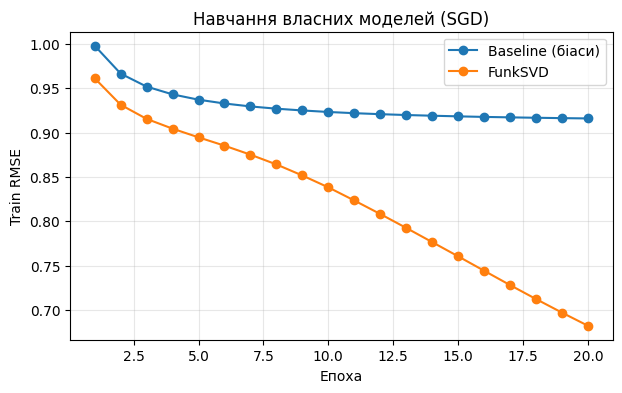

In [18]:
my_baseline = FunkSVDFromScratch(n_factors=0, n_epochs=20, lr=0.005, reg=0.02, random_state=42)
print('Baseline (μ + b_u + b_i):')
my_baseline.fit(train_df)

print()
print('FunkSVD (μ + b_u + b_i + p_u·q_i):')
my_mf = FunkSVDFromScratch(
    n_factors=best_svd_params['n_factors'],
    n_epochs=20,
    lr=best_svd_params['lr_all'],
    reg=best_svd_params['reg_all'],
    random_state=42
)
my_mf.fit(train_df)

base_rmse, base_mae = rmse_mae(test_df['rating'], my_baseline.predict_df(test_df))
my_rmse, my_mae = rmse_mae(test_df['rating'], my_mf.predict_df(test_df))

check_rmse, _ = rmse_mae([p.r_ui for p in svd_predictions], [p.est for p in svd_predictions])
print()
print(f'Перевірка власної метрики на прогнозах Surprise SVD: {check_rmse:.4f} (accuracy.rmse = {svd_rmse:.4f})')

all_results = pd.DataFrame({
    'Model': ['Surprise SVD', 'Surprise KNNBasic', 'Власний Baseline (біаси)', 'Власний FunkSVD'],
    'RMSE': [svd_rmse, knn_rmse, base_rmse, my_rmse],
    'MAE': [svd_mae, knn_mae, base_mae, my_mae]
}).sort_values('RMSE').reset_index(drop=True).round(4)
display(all_results)

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(range(1, my_baseline.n_epochs + 1), my_baseline.train_rmse_history, marker='o', label='Baseline (біаси)')
plt.plot(range(1, my_mf.n_epochs + 1), my_mf.train_rmse_history, marker='o', label='FunkSVD')
plt.xlabel('Епоха')
plt.ylabel('Train RMSE')
plt.title('Навчання власних моделей (SGD)')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [19]:
rated_by_user = set(train_df.loc[train_df['user_id'] == user_id, 'item_id'])
my_top10 = add_titles(my_mf.recommend(user_id, rated_by_user, n=10))
display(my_top10)

print('Перетин з уже оціненими фільмами:', len(set(my_top10['item_id']) & rated_by_user))
print(f'Спільних фільмів із топ-10 моделі {best_model_name}:', len(set(my_top10['item_id']) & set(top10['item_id'])))

,item_id,title,predicted_rating
1,1194,Once Were Warriors (1994),4.4603
2,64,"Shawshank Redemption, The (1994)",4.4496
3,603,Rear Window (1954),4.4270
4,318,Schindler's List (1993),4.4054
5,114,Wallace & Gromit: The Best of Aardman Animation (1996),4.4020
6,97,Dances with Wolves (1990),4.3991
7,98,"Silence of the Lambs, The (1991)",4.3694
8,480,North by Northwest (1959),4.3617
9,496,It's a Wonderful Life (1946),4.3459
10,483,Casablanca (1942),4.3396


Перетин з уже оціненими фільмами: 0
Спільних фільмів із топ-10 моделі SVD: 4


**Висновки до додаткового завдання:**

| Модель | Test RMSE | Test MAE |
|---|---:|---:|
| Surprise SVD | 0.9192 | 0.7234 |
| Власний FunkSVD | 0.9204 | 0.7248 |
| Власний Baseline (біаси) | 0.9394 | 0.7406 |
| Surprise KNNBasic | 1.0120 | 0.7984 |

Власна реалізація FunkSVD з тими самими гіперпараметрами отримала RMSE 0.9204 і MAE 0.7248, що лише на 0.0012 і 0.0014 гірше за бібліотечну SVD; невелика різниця пояснюється іншою випадковою ініціалізацією та порядком обходу оцінок у SGD. Власна функція метрик на прогнозах Surprise SVD дає те саме значення, що й `accuracy.rmse` (0.9192), тож порівняння коректне. Навіть baseline лише з біасами (RMSE 0.9394) точніший за KNNBasic, тобто значну частину варіації оцінок пояснюють загальна «щедрість» користувача та популярність фільму, а латентні фактори додають ще ≈0.019 RMSE. Train RMSE FunkSVD знижується з 0.961 до 0.682 за 20 епох, тоді як тестовий залишається ≈0.920 — цей розрив вказує на початок перенавчання, тому подальше покращення можливе через ранню зупинку за валідаційною вибіркою або сильнішу регуляризацію. Топ-10 для користувача 196 від власної моделі не містить уже оцінених фільмів і має 4 спільні позиції зі списком Surprise SVD (Shawshank Redemption, Schindler's List, North by Northwest, Casablanca). Недоліком реалізації є швидкість: цикл SGD написано на чистому Python, тому навчання повільніше, ніж у скомпільованій Surprise.